<font color="#0D9DF0"><h3><b>ANÁLISE DO DESENVOLVIMENTO TURÍSCO BRASILEIRO</b></h3></font>

**Base de dados:** IBGE, Atlas da Violência  

**Grupo:** Leandro Mendes, Thiago Patente, André e Gabriel Moreira. 

#### Objetivo do trabalho
Investigar se mudanças na taxa de homicídios estão associadas a mudanças nas viagens nacionais por motivo pessoal com destino às UFs.
**Pergunta central:** a violência é um fator que influencia o turismo?
Para investigar essa pergunta, utilizamos um indicador de viagens por
motivo pessoal. Ele não representa exclusivamente turismo de nem quantidade de pessoas únicas.
A análise é descritiva e exploratória: não identifica causalidade.

**Etapas do notebook**
1. Coleta e exploração inicial
2. Limpeza e preparação
3. Análise exploratória
4. Funções de visualização
5. Interpretação das análises
6. Síntese e conclusão

#### Importação das bibliotecas

In [ ]:

import numpy as np
import seaborn as sns
import scipy as scp
import openpyxl as open 

from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

INICIO = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd().resolve()
)

# Procura a raiz do projeto na pasta inicial e nas pastas superiores.
PROJETO = next(
    (pasta for pasta in [INICIO, *INICIO.parents]
     if (pasta / "util").is_dir() and (pasta / "dados").is_dir()),
    None,
)

if PROJETO is None:
    raise FileNotFoundError(
        "Não encontrei a raiz do projeto. "
    )

sys.path.insert(0, str(PROJETO))

from util import (
    ler_tabela_sidra_horizontal,
    ler_csv_flexivel,
    padronizar_serie_por_codigo,
    resumo_duplicados,
    remover_duplicados,
    resumo_ausentes,
    verificar_cobertura,
    filtrar_anos,
    juntar_por_uf_ano,
    variacao_entre_anos,
    indice_base,
    tabela_contingencia,
    teste_robustez,
    grafico_dispersao,
    grafico_total_por_ano,
    grafico_indice_ufs,
    salvar_dataframe,
    salvar_figura,

    ler_titulo_ipeadata,
    identificar_arquivo_ipeadata,
    ler_ipeadata_por_uf,
    ler_ipeadata_serie_anual,
    juntar_indicador,
    variacao_indicador,
    tabela_contingencia_indicador,
    teste_robustez_indicador,
    resumo_choque_indicador,
    grafico_dispersao_indicador,
    grafico_indices_duplos,

     achar_aba, achar_coluna, 
     ler_brent, 
     brent_anual, 
     ler_tabela_anual,
    ler_rodoviario, 
    total_oficial_rodoviario, 
    quedas_bruscas, 
    ranking_ufs,
    juntar_series_anuais, 
    variacoes_anuais, 
    tabela_contingencia_sinais,
    teste_robustez_series, 
    grafico_brent_anual,
    grafico_indices_brent,
    grafico_dispersao_anos, 
    grafico_barras_uf,
    ler_voos,
    ler_tarifa,
    ler_custos
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)



# Mantemos os caminhos relativos à pasta do projeto.
ARQ_TURISMO = PROJETO / "dados" / "Tabela 7266.xlsx"
ARQ_HOMICIDIOS = (
    PROJETO / "dados" / "Taxa de homicídios registrados_estados.csv"
)

ARQUIVOS_IPEA = sorted((PROJETO / "dados").glob("ipeadata*.csv"))


SAIDA = PROJETO / "dados" / "saida"
SAIDA.mkdir(parents=True, exist_ok=True)

ANOS_ANALISE = [2019, 2020, 2021, 2023, 2024]
ANOS_PANDEMIA = [2020, 2021]

PAR_PRINCIPAL = (2023, 2024)
PAR_LONGO = (2019, 2024)

PAR_RECUPERACAO = (2021, 2023)
PAR_CHOQUE = (2019, 2020)

DADOS = PROJETO / "dados"
ARQ_BRENT = next(DADOS.glob("Dados Históricos - Petróleo Brent Futuros.csv"))
ARQ_ROD = DADOS / "ROD_1_5_4_1_1.xlsx"
ARQ_ANUARIO = next(DADOS.glob("anuario_2025 versão final.xlsx"))

# Apenas cenários exploratórios de sensibilidade.
# Nenhuma UF é retirada da base principal.
CENARIOS = {
    "Todas as UFs": [],
    "Sem Roraima": ["RR"],
    "Sem Roraima e Amapá": ["RR", "AP"],
}

CHAVES = ["cod_ibge", "ano"]


---

## 1. Coleta de Dados
**Etapa atual:  COLETA**

O primeiro passo é carregar a base da Pesquisa Nacional por Amostra de Domicílios Contínua anual
Tabela 7266 - Viagens nacionais por motivo pessoal realizadas pelos moradores dos domicílios no período de referência dos últimos três meses, por principal Unidade da Federação de destino.
Depois a taxa de homocidio provinda pela atlas da violência. 

In [ ]:
# Informar o caminho correto do arquivo disponibilizado para a atividade, como a tabela é toda construída horizontal, então foi criada uma função para esse caso.
turismo_bruto = ler_tabela_sidra_horizontal(
    ARQ_TURISMO,
    aba="Tabela",
    nome_valor="viagens_mil",
)

# A tabela de homicídio  
homic_csv = ler_csv_flexivel(ARQ_HOMICIDIOS)


In [11]:
print("Arquivo de viagens:", ARQ_TURISMO)
print("Arquivo de homicídios:", ARQ_HOMICIDIOS)

Arquivo de viagens: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\Tabela 7266.xlsx
Arquivo de homicídios: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\Taxa de homicídios registrados_estados.csv


## 2. Exploração Inicial dos Dados
**Etapa atual:  EXPLORAÇÃO INICIAL**

Antes de tratar os dados, verificar a estrutura do DataFrame e entender os itens em cada colunas.
Verificamos as primeiras linhas, nomes das colunas, tipos,
quantidade de registros e estatísticas descritivas.

In [15]:
print("\nInformações das viagens:")
turismo_bruto.info()

print("\nInformações dos homicídios:")
homic_csv.info()


Informações das viagens:
<class 'pandas.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   cod_ibge     135 non-null    int64  
 1   uf           135 non-null    str    
 2   estado       135 non-null    str    
 3   ano          135 non-null    int64  
 4   viagens_mil  135 non-null    float64
dtypes: float64(1), int64(2), str(2)
memory usage: 5.4 KB

Informações dos homicídios:
<class 'pandas.DataFrame'>
RangeIndex: 675 entries, 0 to 674
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Período    675 non-null    str    
 1   Região ID  675 non-null    int64  
 2   Valor      675 non-null    float64
dtypes: float64(1), int64(1), str(1)
memory usage: 15.9 KB


In [14]:
# Visualizar informações gerais do DataFrame
print("Primeiras linhas das viagens:")
print(turismo_bruto.head())

print("\nPrimeiras linhas dos homicídios:")
print(homic_csv.head())

Primeiras linhas das viagens:
   cod_ibge  uf    estado   ano  viagens_mil
0        11  RO  Rondônia  2019         93.0
1        12  AC      Acre  2019         40.0
2        13  AM  Amazonas  2019        162.0
3        14  RR   Roraima  2019         25.0
4        15  PA      Pará  2019        773.0

Primeiras linhas dos homicídios:
                    Período  Região ID  Valor
0  2000-01-15T00:00:00.000Z         11  33.85
1  2000-01-15T00:00:00.000Z         12  18.05
2  2000-01-15T00:00:00.000Z         13  19.36
3  2000-01-15T00:00:00.000Z         14  38.26
4  2000-01-15T00:00:00.000Z         15  12.41


In [18]:
# Consultar estatísticas descritivas
print("Estatísticas das viagens por ano:")
print(
    turismo_bruto.groupby("ano")["viagens_mil"]
    .describe()
    .round(1)
)
print("\nAnos das viagens:")
print(sorted(turismo_bruto["ano"].unique()))

print("\nUFs identificadas:")
print(sorted(turismo_bruto["uf"].unique()))

Estatísticas das viagens por ano:
      count   mean    std   min    25%    50%    75%     max
ano                                                         
2019   27.0  632.1  709.9  25.0  203.5  357.0  760.5  3137.0
2020   27.0  413.4  506.1  14.0  111.5  243.0  577.0  2408.0
2021   27.0  380.5  454.7   6.0  100.0  237.0  503.0  2115.0
2023   27.0  636.0  822.2  13.0  156.0  289.0  813.5  3935.0
2024   27.0  630.5  769.3  25.0  172.0  331.0  779.5  3607.0

Anos das viagens:
[np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2023), np.int64(2024)]

UFs identificadas:
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


**Anotações do grupo**
- No arquivo de homicidio estão disponiveis as colunas:     Período  Região ID  Valor e o periodo é de 2000 a 2024
- No arquivo de turismo estão  as colunas:    cod_ibge  uf    estado   ano  viagens_mil e o periodo é de 2019 a 2024.
- Precisamos padronizar o período e o código das UFs no CSV.
- A base de viagens tem 135 registros: 27 UFs em cinco anos.
- O CSV de homicídios tem 675 registros e uma série temporal maior.
- Os dados de viagens não incluem 2022.
- Valores de viagens estão em milhares, não em unidades.

## 3. Limpeza de Dados
**Etapa atual:  TRATAMENTO**
Primeiro deve padronizar os CSV:
- Região ID → cod_ibge.
- Período → ano.
- Valor → taxa_homicidios.

Depois, deve verificar dados ausentes e duplicados.
Não pode importar valores: médias artificiais poderiam alterar as variações e as associações investigadas.

In [ ]:
# padronizar taxa por estado/federação
homic_bruto = padronizar_serie_por_codigo(
    homic_csv,
    nome_valor="taxa_homicidios",
    col_codigo="Região ID",
    col_periodo="Período",
    col_valor="Valor",
)
print(homic_bruto.head())


   cod_ibge  uf    estado   ano  taxa_homicidios
0        11  RO  Rondônia  2000            33.85
1        12  AC      Acre  2000            18.05
2        13  AM  Amazonas  2000            19.36
3        14  RR   Roraima  2000            38.26
4        15  PA      Pará  2000            12.41


In [22]:
# Verificar a quantidade de registros duplicados
print("Diagnóstico de duplicados:")
for nome, df in {
    "Viagens": turismo_bruto,
    "Homicídios": homic_bruto,
}.items():
    duplicados = resumo_duplicados(df, CHAVES)
    print(f"\n{nome}: {len(duplicados)} linhas com chaves repetidas")
    if len(duplicados):
        print(duplicados)

print("\nDiagnóstico de ausentes — viagens:")
print(resumo_ausentes(turismo_bruto))

print("\nDiagnóstico de ausentes — homicídios:")
print(resumo_ausentes(homic_bruto))


Diagnóstico de duplicados:

Viagens: 0 linhas com chaves repetidas

Homicídios: 0 linhas com chaves repetidas

Diagnóstico de ausentes — viagens:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Diagnóstico de ausentes — homicídios:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []


In [ ]:
# Remover primeiro registros completamente idênticos.
# Se a mesma UF/ano tiver registros diferentes, deve interromper  a análise
# em vez de escolher arbitrariamente qual valor manter.
turismo_sem_identicos = turismo_bruto.drop_duplicates()
homic_sem_identicos = homic_bruto.drop_duplicates()

for nome, df in {
    "Viagens": turismo_sem_identicos,
    "Homicídios": homic_sem_identicos,
}.items():
    conflitos = resumo_duplicados(df, CHAVES)
    if len(conflitos):
        print(conflitos)
        raise ValueError(
            f"{nome}: conferir registros conflitantes por UF e ano."
        )

turismo_limpo = remover_duplicados(turismo_sem_identicos, CHAVES)
homic_limpo = remover_duplicados(homic_sem_identicos, CHAVES)

# Excluímos apenas linhas com ausência nas colunas necessárias.
turismo_limpo = turismo_limpo.dropna(
    subset=CHAVES + ["uf", "estado", "viagens_mil"]
).copy()

homic_limpo = homic_limpo.dropna(
    subset=CHAVES + ["taxa_homicidios"]
).copy()

auditoria = pd.DataFrame([
    {
        "base": "Viagens",
        "linhas_antes": len(turismo_bruto),
        "linhas_depois": len(turismo_limpo),
        "linhas_removidas": len(turismo_bruto) - len(turismo_limpo),
    },
    {
        "base": "Homicídios",
        "linhas_antes": len(homic_bruto),
        "linhas_depois": len(homic_limpo),
        "linhas_removidas": len(homic_bruto) - len(homic_limpo),
    },
])

print(auditoria)

         base  linhas_antes  linhas_depois  linhas_removidas
0     Viagens           135            135                 0
1  Homicídios           675            675                 0


**Decisões de tratamento**
 - Na execução apresentada, não foram encontrados ausentes ou duplicados.
   Portanto, a limpeza não exigiu excluir registros.

 - Uma ausência futura não será preenchida artificialmente. Também será
   necessário verificar se ela compromete a cobertura por UF e ano.

## 4. Transformação e Preparação dos Dados


- Selecionar os anos disponíveis nas duas fontes.
- Padronizar tipos numéricos.
- Conferir a cobertura.
- Integrar por código IBGE e ano.
- Preparar agrupamentos nacionais e comparações temporais.

-Não usamos a posição das linhas para relacionar as UFs.

In [ ]:
# Realizar aqui as transformações necessárias, se houver
turismo = filtrar_anos(turismo_limpo, ANOS_ANALISE).copy()
homic = filtrar_anos(homic_limpo, ANOS_ANALISE).copy()

for df in [turismo, homic]:
    df["cod_ibge"] = pd.to_numeric(
        df["cod_ibge"], errors="raise"
    ).astype(int)
    df["ano"] = pd.to_numeric(
        df["ano"], errors="raise"
    ).astype(int)

turismo["viagens_mil"] = pd.to_numeric(
    turismo["viagens_mil"], errors="raise"
)
homic["taxa_homicidios"] = pd.to_numeric(
    homic["taxa_homicidios"], errors="raise"
)

if turismo["viagens_mil"].lt(0).any():
    raise ValueError("Há valores negativos nas viagens.")

if homic["taxa_homicidios"].lt(0).any():
    raise ValueError("Há valores negativos nas taxas.")

print("Cobertura — viagens:")
print(verificar_cobertura(turismo))

print("\nCobertura — homicídios:")
print(verificar_cobertura(homic))

# %%
# Conferência independente das chaves antes da junção.
chaves_esperadas = pd.MultiIndex.from_product(
    [turismo["cod_ibge"].unique(), ANOS_ANALISE],
    names=CHAVES,
)

if turismo["cod_ibge"].nunique() != 27:
    raise ValueError("A base de viagens deve conter 27 UFs.")

for nome, df in {"Viagens": turismo, "Homicídios": homic}.items():
    chaves_observadas = pd.MultiIndex.from_frame(df[CHAVES])
    if (
        len(chaves_esperadas.difference(chaves_observadas))
        or len(chaves_observadas.difference(chaves_esperadas))
    ):
        raise ValueError(f"{nome}: cobertura incompleta ou inesperada.")

base = juntar_por_uf_ano(turismo, homic)
base = base.sort_values(["ano", "cod_ibge"]).reset_index(drop=True)

if len(base) != 27 * len(ANOS_ANALISE):
    raise ValueError("Quantidade inesperada de registros após a junção.")

if base.duplicated(CHAVES).any():
    raise ValueError("A junção produziu chaves duplicadas.")

if base[["viagens_mil", "taxa_homicidios"]].isna().any().any():
    raise ValueError("A base integrada contém valores ausentes.")

print(base.head(10))

# %%
# Agrupamento: soma das estimativas estaduais de viagens.
total = base.groupby("ano")["viagens_mil"].sum().to_frame()
total["variacao_vs_2019_pct"] = (
    (total["viagens_mil"] / total.loc[2019, "viagens_mil"] - 1) * 100
).round(1)

var_principal = variacao_entre_anos(base, *PAR_PRINCIPAL)
var_longo = variacao_entre_anos(base, *PAR_LONGO)

comparacoes_pandemia = {
    ano: variacao_entre_anos(base, 2019, ano)
    for ano in ANOS_PANDEMIA
}

indice = indice_base(base, "viagens_mil", ano_base=2019)

print(total)



Cobertura — viagens:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True
2024   27      True

Cobertura — homicídios:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True
2024   27      True
   cod_ibge  uf     estado   ano  viagens_mil  taxa_homicidios
0        11  RO   Rondônia  2019         93.0            26.10
1        12  AC       Acre  2019         40.0            37.88
2        13  AM   Amazonas  2019        162.0            39.08
3        14  RR    Roraima  2019         25.0            37.86
4        15  PA       Pará  2019        773.0            40.51
5        16  AP      Amapá  2019         45.0            46.31
6        17  TO  Tocantins  2019        175.0            29.90
7        21  MA   Maranhão  2019        439.0            24.53
8        22  PI      Piauí  2019        508.0            17.14
9        23  CE      Ceará  2019        748.


 **Atenção às unidades:** taxas estaduais de homicídios não podem ser
 somadas para obter uma taxa nacional. Para calcular uma taxa nacional,
 seriam necessários os óbitos e as populações correspondentes.

## 5. Análise exploratória dos dados

### 5.1. Turismo × violência
Os dados utilizados foram dos anos de 2023 → 2024

Os anos de 2020 e 2021 foram separados devido a pandemia que sera analisada como caso a parte.

Isso não elimina todos os fatores de confusão nem garante ausência
de efeitos posteriores da pandemia.

**Pergunta 1** — A queda dos homicídios acompanhou o aumento das viagens?

A tabela cruza o sentido das duas mudanças em cada UF.


In [27]:
contingencia_principal = tabela_contingencia(var_principal)
print(contingencia_principal)

viagens_mov  caiu  subiu  Total
taxa_mov                       
caiu           10     15     25
subiu           0      2      2
Total          10     17     27


## Analisando o resultado de cima pode-se afirmar que:

- Em 10, as viagens também caíram.
- Em 15, as viagens subiram.

Portanto, **redução de homicídios** não foi acompanhada de aumento das viagens em todas as UFs.

## Nas 2 UFs onde a taxa de homicídios subiu:

- Em nenhuma, as viagens caíram.
- Nas 2, as viagens subiram.

## Independentemente do movimento dos homicídios:

- As viagens caíram em 10 UFs.
- As viagens subiram em 17 UFs.
- Foram analisadas 27 UFs.

**Pergunta 2** — As variações apresentam associação?

Foi calculado os resultados exploratórios com as funções existentes.

Os cenários sem RR e AP avaliam sensibilidade; não representam uma
justificativa para excluir essas UFs do resultado principal.

In [ ]:
robustez = teste_robustez(var_principal, CENARIOS)
print(robustez)

               cenario   n  pearson  spearman  inclinacao_pct  r_critico_5pct
0         Todas as UFs  27   -0.109    -0.037          -0.555           0.359
1          Sem Roraima  26    0.150     0.061           0.362           0.365
2  Sem Roraima e Amapá  25   -0.041    -0.009          -0.166           0.371


Ao o que tudo indica as correlações estão bem abaixa de 1 o que indica que não há quase nenhuma correlação.
Não significa que a violência não influencia no turismo mas que o resultado é baixo demais para se quer responder.

**Pergunta 3** —  O que muda na comparação 2019 → 2024?

Esta comparação é complementar, não uma confirmação independente.

Ela envolve o período da pandemia e diferenças na apresentação metodológica da fonte de viagens.

In [29]:
contingencia_longa = tabela_contingencia(var_longo)
robustez_longa = teste_robustez(var_longo, CENARIOS)

print(contingencia_longa)
print(robustez_longa)

viagens_mov  caiu  subiu  Total
taxa_mov                       
caiu           11      6     17
subiu           6      4     10
Total          17     10     27
               cenario   n  pearson  spearman  inclinacao_pct  r_critico_5pct
0         Todas as UFs  27    0.238     0.180           0.667           0.359
1          Sem Roraima  26    0.271     0.195           0.785           0.365
2  Sem Roraima e Amapá  25    0.314     0.175           0.851           0.371


Na comparação entre 2019 e 2024, das 17 UFs em que a taxa de homicídios caiu, 11 tiveram queda nas viagens e seis tiveram aumento. Nas dez UFs em que os homicídios subiram, seis tiveram queda nas viagens e quatro tiveram aumento.

As correlações foram positivas e fracas(abaixo de 1.0), mesmo após excluir Roraima e Amapá por serem dados com extaploração alta. Portanto, não foi observada uma associação consistente entre redução dos homicídios e aumento das viagens.

Isso não prova que a violência não influencie as viagens devido a baixa correlação, baixa quantidade e dados e também os dados vindos da tabela de turismo não filtra viagens exclusivamente por entretenimento/cultura e culinária(características de viagem de turismo ).

### 5.2. Análise dos anos da pandemia e sua exclusão da análise principal

**Pergunta 4** — Quanto as viagens mudaram em relação a 2019?


In [30]:
print(total)


      viagens_mil  variacao_vs_2019_pct
ano                                    
2019      17066.0                   0.0
2020      11162.0                 -34.6
2021      10274.0                 -39.8
2023      17171.0                   0.6
2024      17024.0                  -0.2


O resultado demonstra que os anos de 2020 e 2021 tiveram uma variação enorme na taxa de viagens, isso indica o impacto da pandemia e o por quê da decisão de exclusão dos dados de 2020 e 2021 na analises.

**Pergunta 5** — A queda das viagens ocorreu em todas as UFs?


In [31]:
resumo_pandemia = []

for ano, comparacao in comparacoes_pandemia.items():
    queda_viagens = comparacao["viagens_mov"].eq("caiu")
    queda_taxa = comparacao["taxa_mov"].eq("caiu")
    quedas_simultaneas = comparacao.loc[queda_viagens & queda_taxa]

    resumo_pandemia.append({
        "ano": ano,
        "ufs_com_queda_viagens": int(queda_viagens.sum()),
        "ufs_com_queda_taxa": int(queda_taxa.sum()),
        "ufs_com_ambas_as_quedas": len(quedas_simultaneas),
    })

    print(f"\n{ano}:")
    print(f"Viagens caíram em {int(queda_viagens.sum())} de 27 UFs.")
    print(
        "UFs com queda simultânea da taxa e das viagens:",
        quedas_simultaneas["uf"].tolist(),
    )

resumo_pandemia = pd.DataFrame(resumo_pandemia)
print("\nResumo:")
print(resumo_pandemia)


2020:
Viagens caíram em 27 de 27 UFs.
UFs com queda simultânea da taxa e das viagens: ['AC', 'AM', 'RR', 'PA', 'MG', 'SC', 'RS', 'MS', 'GO', 'DF']

2021:
Viagens caíram em 27 de 27 UFs.
UFs com queda simultânea da taxa e das viagens: ['AC', 'PA', 'TO', 'RN', 'PE', 'AL', 'SE', 'MG', 'SP', 'SC', 'RS', 'MT', 'GO', 'DF']

Resumo:
    ano  ufs_com_queda_viagens  ufs_com_queda_taxa  ufs_com_ambas_as_quedas
0  2020                     27                  10                       10
1  2021                     27                  14                       14



A pandemia não influênciou todos os estados de forma simultânea porém no auge dela(2021), uma parcela grande dos estados sofreram uma queda.


**Pergunta 6** — Quais são as menores estimativas na pandemia?
- Identificar valores pequenos ajuda a contextualizar oscilações
- percentuais. Não permite, sozinho, medir o erro amostral.

In [33]:
menores_estimativas = (
    base.loc[base["ano"].isin(ANOS_PANDEMIA)]
    .nsmallest(6, "viagens_mil")
    [["ano", "uf", "viagens_mil"]]
)
print(menores_estimativas)


     ano  uf  viagens_mil
59  2021  AP          6.0
57  2021  RR          8.0
28  2020  AC         14.0
32  2020  AP         15.0
55  2021  AC         16.0
30  2020  RR         17.0


As menores estimativas na pandemia ocorreram em Amapá, Roraima e Acre, entre 6 mil e 17 mil viagens. 

Esses valores, isoladamente, não demonstram influência da violência.

## 6. Funções de visualização gráfica



Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\total_viagens_por_ano.png


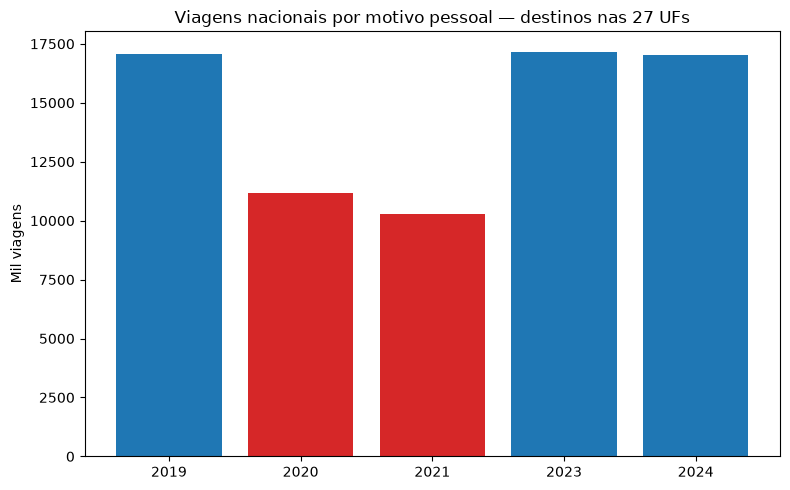

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\dispersao_2023_2024.png


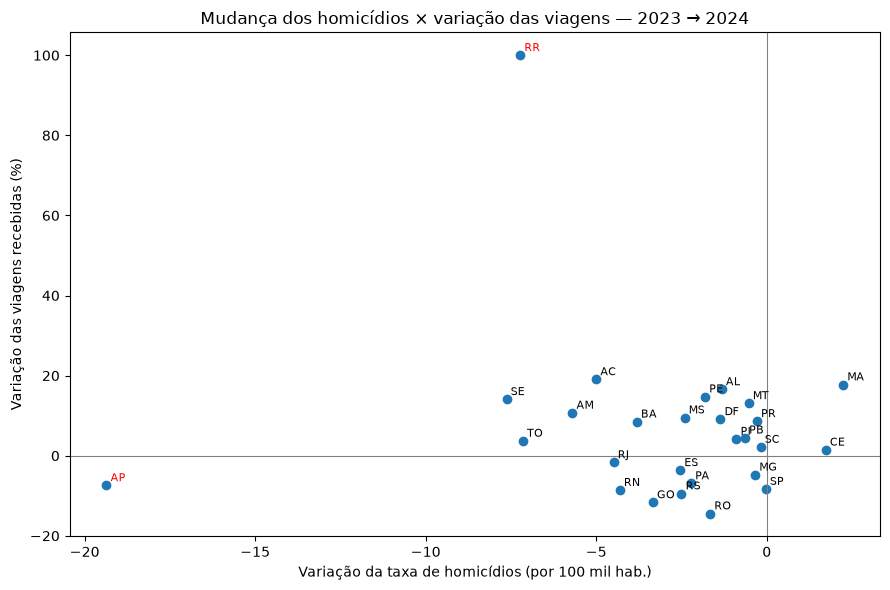

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\dispersao_2019_2024.png


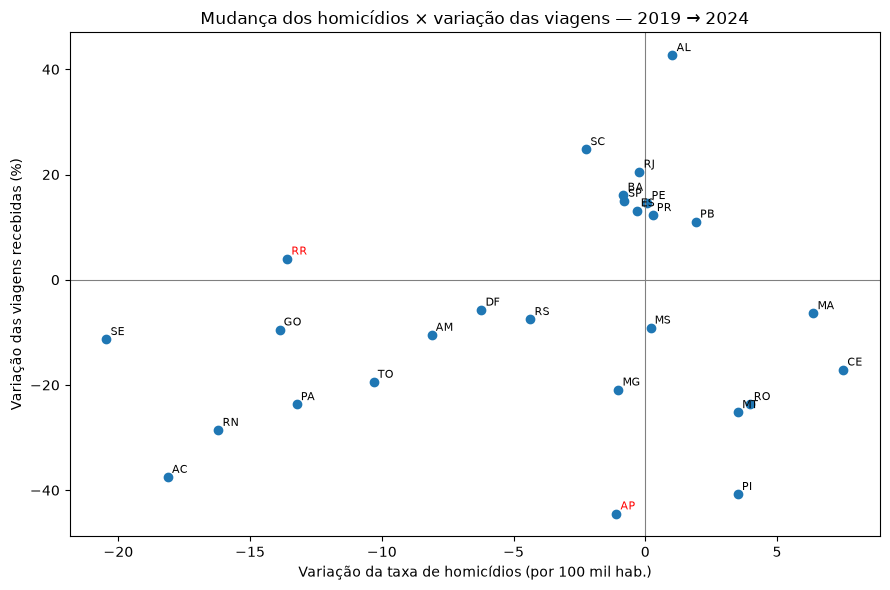

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\dispersao_pandemia_2020.png


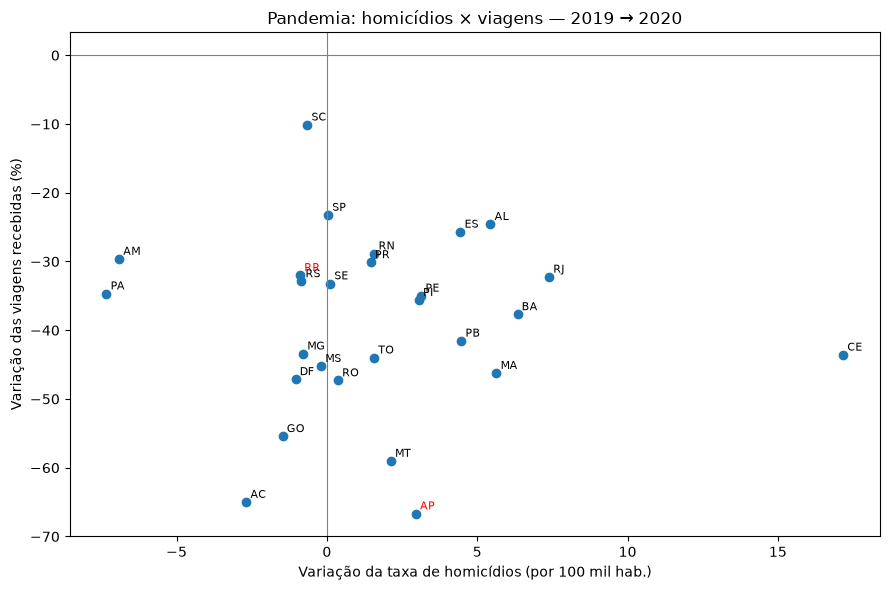

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\dispersao_pandemia_2021.png


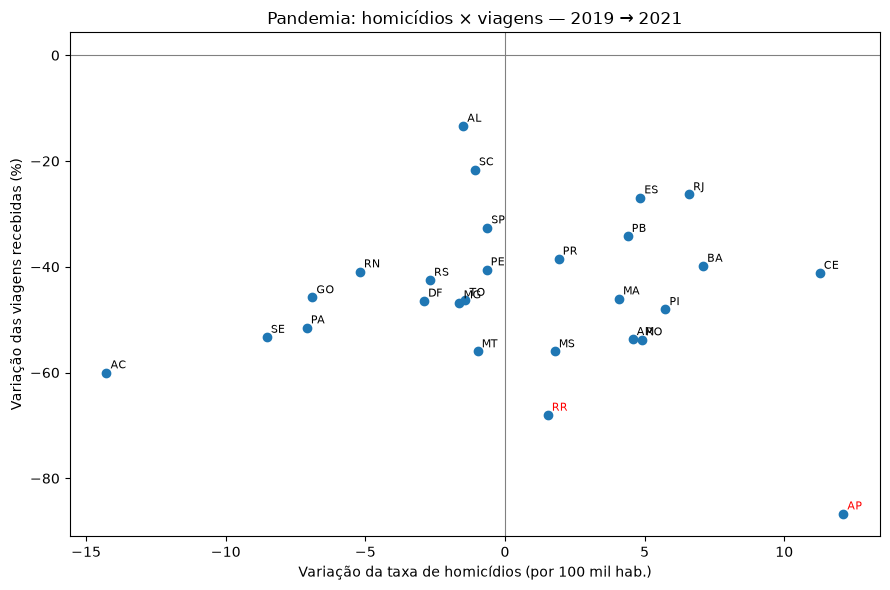

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\indice_viagens_ufs.png


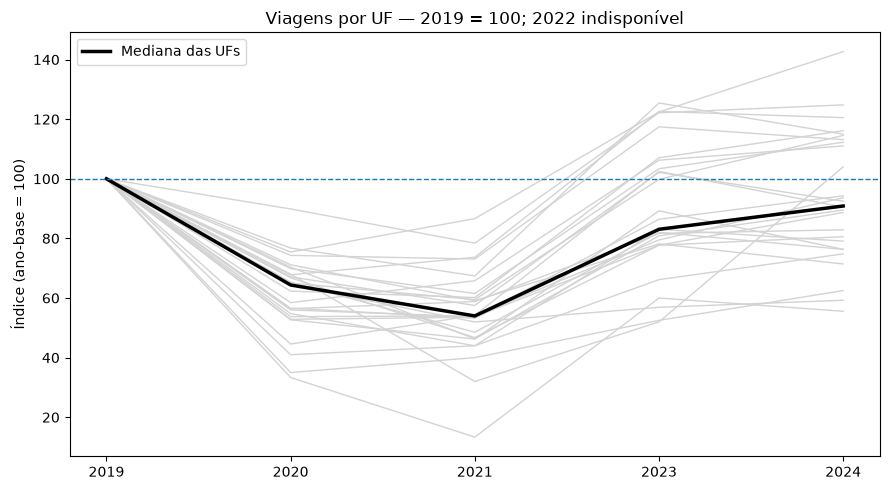

In [34]:
fig_total = grafico_total_por_ano(
    base,
    "viagens_mil",
    destaque=ANOS_PANDEMIA,
    titulo="Viagens nacionais por motivo pessoal — destinos nas 27 UFs",
    rotulo_y="Mil viagens",
)
salvar_figura(fig_total, str(SAIDA / "total_viagens_por_ano.png"))
plt.show()
plt.close(fig_total)

# %%
fig_disp = grafico_dispersao(
    var_principal,
    "Mudança dos homicídios × variação das viagens — 2023 → 2024",
    destacar=("RR", "AP"),
)
salvar_figura(fig_disp, str(SAIDA / "dispersao_2023_2024.png"))
plt.show()
plt.close(fig_disp)

# %%
fig_longo = grafico_dispersao(
    var_longo,
    "Mudança dos homicídios × variação das viagens — 2019 → 2024",
    destacar=("RR", "AP"),
)
salvar_figura(fig_longo, str(SAIDA / "dispersao_2019_2024.png"))
plt.show()
plt.close(fig_longo)

# %%
for ano, comparacao in comparacoes_pandemia.items():
    fig_pandemia = grafico_dispersao(
        comparacao,
        f"Pandemia: homicídios × viagens — 2019 → {ano}",
        destacar=("RR", "AP"),
    )
    salvar_figura(
        fig_pandemia,
        str(SAIDA / f"dispersao_pandemia_{ano}.png"),
    )
    plt.show()
    plt.close(fig_pandemia)

# %%
fig_ind = grafico_indice_ufs(
    indice,
    "Viagens por UF — 2019 = 100; 2022 indisponível",
)
salvar_figura(fig_ind, str(SAIDA / "indice_viagens_ufs.png"))
plt.show()
plt.close(fig_ind)

In [ ]:
# Testar a função criada em uma das análises

## 7. Interpretação das Visualizações
### 7.1. Viagens × violência em 2023 → 2024

### Conforme a execução fornecida:

- A taxa de homicídios caiu em 25 UFs.
- Nessas UFs, as viagens aumentaram em 15 e diminuíram em 10.
- Nas duas UFs com aumento da taxa, as viagens também aumentaram.

Portanto, a queda da violência não foi acompanhada de aumento das viagens em todas as UFs.

A correlação de Pearson com todas as UFs foi aproximadamente -0,109 e a de Spearman, -0,037: valores próximos de zero nessa comparação.

Nos cenários selecionados, Pearson mudou de sinal e permaneceu próximo de zero. Isso não prova a correlação mas não comprova ausência de influência da violência nas decisões individuais de viagem.

### 7.2. Comparação 2019 → 2024

Pearson foi aproximadamente 0,238 com todas as UFs, diferente do sinal observado na comparação principal.

O resultado descreve essa comparação específica. O intervalo inclui pandemia, recuperação e diferenças metodológicas, impedindo atribuir as mudanças exclusivamente à violência.

### 7.3. Pandemia

No resultado obtido , a soma das estimativas por UF foi:

| Ano | Mil viagens | Variação em relação a 2019 |
|---|---:|---:|
| 2019 | 17.066 | 0,0% |
| 2020 | 11.162 | -34,6% |
| 2021 | 10.274 | -39,8% |
| 2023 | 17.171 | +0,6% |
| 2024 | 17.024 | -0,2% |

- Em 2020 e 2021, todas as UFs receberam menos viagens que em 2019.
- Em 2020, dez UFs apresentaram queda simultânea da taxa de homicídios e das viagens.

Esse padrão é compatível com um choque comum associado à pandemia, não com uma explicação baseada exclusivamente nos homicídios.

A análise não estima causalmente o efeito da pandemia porém há uma forte evidência que houve sim causa e efeito da pandemia com o número de viagens.

**Observações da fonte:**

- As estimativas se referem às viagens no período de referência dos últimos três meses, não a todas as viagens de um ano.
- A apresentação de 2019 exige conferência das notas metodológicas.
- Somar valores estaduais arredondados pode produzir pequena diferença em relação ao total Brasil publicado.
- Um índice de 2019 = 100 compara movimentos relativos, não volumes.
- Não existem observações de 2022: uma eventual linha entre 2021 e 2023 não deve ser interpretada como estimativa daquele ano.


## 8. Síntese dos Principais Insights

1. **Não há movimento uniforme entre os indicadores.**
    A queda dos homicídios em 2023 → 2024 ocorreu tanto em UFs com aumento quanto com diminuição das viagens.

2. **A associação na comparação principal é próxima de zero.**
    Pearson e Spearman apresentam coeficientes pequenos nos resultados fornecidos.

3. **A pandemia corresponde a uma redução disseminada das viagens.**
    Todas as 27 UFs apresentaram quedas em 2020 e 2021 frente a 2019.

4. **O contexto e o indicador importam.**
    Viagens por motivo pessoal não isolam lazer, e a taxa estadual não representa diretamente a segurança dos destinos turísticos.

 **Aplicação prática:** os resultados ajudam a contextualizar mudanças nas viagens, mas não permitem prever quanto uma redução dos homicídios aumentaria o turismo.

## 9. Conclusão e Reflexão

### Resposta à pergunta central

**A influência causal da violência sobre o turismo permanece inconclusiva com as bases e o desenho utilizados.**

A comparação 2023 → 2024 não apresenta uma associação linear ou monotônica expressiva nos resultados fornecidos. Isso não significa que a violência não influencie o turismo, significa que esta análise não consegue identificar ou quantificar essa influência.

### Principais limitações

- Apenas cinco anos com dados de viagens e ausência de 2022.
- O recorte principal tem somente uma mudança anual por UF, ou seja, um evento local como uma operação policial violenta pode inteferir nas busca por viagem e esse forma de dados anual não demonstra essa causa e efeito.
- O indicador inclui diferentes motivos pessoais, não apenas lazer.
- As viagens são estimativas amostrais, e seus erros não foram incorporados aos cálculos de associação.
- A violência é representada apenas pela taxa de homicídios.
- Os dados estaduais ocultam diferenças entre municípios.
- Não foram controlados renda, transporte, eventos, atrativos,infraestrutura ou outros determinantes para turismo.
- A pandemia dificulta separar movimentos associados à violência de outros fatores simultâneos.
- A comparabilidade de 2019 exige cautela metodológica.

## 10. Referências


- **IBGE — Instituto Brasileiro de Geografia e Estatística.**
     Pesquisa Nacional por Amostra de Domicílios Contínua.
   Tabela 7266: viagens nacionais por motivo pessoal, por principal
   Unidade da Federação de destino. SIDRA.
  Disponível em: https://sidra.ibge.gov.br/tabela/7266

- **IPEA; Fórum Brasileiro de Segurança Pública.**
   Atlas da Violência. Indicador de taxa de homicídios por UF
   utilizado no arquivo CSV.
  Disponível em: https://www.ipea.gov.br/atlasviolencia/